# The Happiness Panel
### Five years of country scores, shared drivers and divergent paths

A longitudinal reading of the World Happiness Report files from 2015 to 2019. The analysis moves from a harmonized country-year panel to cross-country associations, regional contrasts and country-level change.

The central distinction is between **association across countries** and **change within a country over time**. They answer different questions and are treated separately throughout the notebook.

## Data architecture

The five source files use different labels for several of the same measures. A common schema makes the country-year records comparable while retaining the original score values.

The source folder is the Desktop directory `world happiness report data`. Its five files are named `2015.csv` through `2019.csv`.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.io as pio
from IPython.display import display

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 150)
pd.set_option("display.float_format", "{:,.3f}".format)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (11, 6)
plt.rcParams["axes.titleweight"] = "bold"
plt.rcParams["axes.labelcolor"] = "#344054"
plt.rcParams["text.color"] = "#243247"

data_dir = Path.home() / "Desktop" / "world happiness report data"

data = {
    year: pd.read_csv(data_dir / f"{year}.csv")
    for year in range(2015, 2020)
}

print("Years loaded:", ", ".join(map(str, data.keys())))
print("Source rows:", sum(frame.shape[0] for frame in data.values()))

Years loaded: 2015, 2016, 2017, 2018, 2019
Source rows: 782


## One vocabulary across five editions

`Family` becomes `social_support`; the GDP, health, freedom and corruption fields are aligned with their later names. Region is retained where the source provides it. Fields that do not exist in a given edition remain missing rather than being reconstructed.

In [2]:
column_maps = {
    2015: {
        "Country": "country",
        "Region": "region",
        "Happiness Rank": "rank",
        "Happiness Score": "happiness_score",
        "Economy (GDP per Capita)": "gdp_per_capita",
        "Family": "social_support",
        "Health (Life Expectancy)": "health_life_expectancy",
        "Freedom": "freedom",
        "Generosity": "generosity",
        "Trust (Government Corruption)": "corruption",
        "Dystopia Residual": "dystopia_residual",
    },
    2016: {
        "Country": "country",
        "Region": "region",
        "Happiness Rank": "rank",
        "Happiness Score": "happiness_score",
        "Economy (GDP per Capita)": "gdp_per_capita",
        "Family": "social_support",
        "Health (Life Expectancy)": "health_life_expectancy",
        "Freedom": "freedom",
        "Generosity": "generosity",
        "Trust (Government Corruption)": "corruption",
        "Dystopia Residual": "dystopia_residual",
    },
    2017: {
        "Country": "country",
        "Happiness.Rank": "rank",
        "Happiness.Score": "happiness_score",
        "Economy..GDP.per.Capita.": "gdp_per_capita",
        "Family": "social_support",
        "Health..Life.Expectancy.": "health_life_expectancy",
        "Freedom": "freedom",
        "Generosity": "generosity",
        "Trust..Government.Corruption.": "corruption",
        "Dystopia.Residual": "dystopia_residual",
    },
    2018: {
        "Country or region": "country",
        "Overall rank": "rank",
        "Score": "happiness_score",
        "GDP per capita": "gdp_per_capita",
        "Social support": "social_support",
        "Healthy life expectancy": "health_life_expectancy",
        "Freedom to make life choices": "freedom",
        "Generosity": "generosity",
        "Perceptions of corruption": "corruption",
    },
    2019: {
        "Country or region": "country",
        "Overall rank": "rank",
        "Score": "happiness_score",
        "GDP per capita": "gdp_per_capita",
        "Social support": "social_support",
        "Healthy life expectancy": "health_life_expectancy",
        "Freedom to make life choices": "freedom",
        "Generosity": "generosity",
        "Perceptions of corruption": "corruption",
    },
}

standard_columns = [
    "year", "country", "region", "rank", "happiness_score",
    "gdp_per_capita", "social_support", "health_life_expectancy",
    "freedom", "generosity", "corruption", "dystopia_residual"
]

frames = []
for year, source in data.items():
    frame = source.rename(columns=column_maps[year]).copy()
    frame["year"] = year
    frame = frame.reindex(columns=standard_columns)
    frame["country"] = frame["country"].astype("string").str.strip()
    frame["region"] = frame["region"].astype("string").str.strip()

    numeric_columns = [
        "rank", "happiness_score", "gdp_per_capita", "social_support",
        "health_life_expectancy", "freedom", "generosity",
        "corruption", "dystopia_residual"
    ]
    frame[numeric_columns] = frame[numeric_columns].apply(
        pd.to_numeric, errors="coerce"
    )
    frames.append(frame)

happiness = pd.concat(frames, ignore_index=True)
happiness = happiness.sort_values(["country", "year"]).reset_index(drop=True)

print(f"Combined panel: {happiness.shape[0]:,} rows × {happiness.shape[1]} columns")
display(happiness.head())

Combined panel: 782 rows × 12 columns


,year,country,region,rank,happiness_score,gdp_per_capita,social_support,health_life_expectancy,freedom,generosity,corruption,dystopia_residual
0,2015,Afghanistan,Southern Asia,153,3.575,0.320,0.303,0.303,0.234,0.365,0.097,1.952
1,2016,Afghanistan,Southern Asia,154,3.360,0.382,0.110,0.173,0.164,0.313,0.071,2.146
2,2017,Afghanistan,<NA>,141,3.794,0.401,0.582,0.181,0.106,0.312,0.061,2.151
3,2018,Afghanistan,<NA>,145,3.632,0.332,0.537,0.255,0.085,0.191,0.036,NaN
4,2019,Afghanistan,<NA>,154,3.203,0.350,0.517,0.361,0.000,0.158,0.025,NaN


## Coverage and data quality

The country-year key is the unit of analysis. Countries that appear in all five editions form the balanced panel used for average-score comparisons and 2015–2019 change calculations. This avoids ranking countries on unequal time windows.

In [3]:
coverage = (
    happiness.groupby("year")
    .agg(
        country_records=("country", "size"),
        distinct_countries=("country", "nunique"),
        mean_score=("happiness_score", "mean"),
        median_score=("happiness_score", "median"),
        score_std=("happiness_score", "std"),
    )
    .round(3)
)

country_year_counts = happiness.groupby("country")["year"].nunique()
complete_countries = country_year_counts[country_year_counts.eq(5)].index
balanced_panel = happiness[happiness["country"].isin(complete_countries)].copy()

score_pivot = balanced_panel.pivot(
    index="country", columns="year", values="happiness_score"
)

country_metrics = [
    "happiness_score", "gdp_per_capita", "social_support",
    "health_life_expectancy", "freedom", "generosity", "corruption"
]
country_profile = (
    balanced_panel.groupby("country")[country_metrics]
    .mean()
)

data_quality = pd.DataFrame({
    "missing_rows": happiness.isna().sum(),
    "missing_pct": happiness.isna().mean().mul(100)
}).sort_values("missing_rows", ascending=False)

duplicate_keys = happiness.duplicated(["country", "year"]).sum()

print(f"Total country-year records: {len(happiness):,}")
print(f"Distinct country labels: {happiness['country'].nunique():,}")
print(f"Countries present in all five years: {len(complete_countries):,}")
print(f"Balanced-panel records: {len(balanced_panel):,}")
print(f"Duplicate country-year keys: {duplicate_keys}")
display(coverage)
display(data_quality.round(2))

Total country-year records: 782
Distinct country labels: 170
Countries present in all five years: 141
Balanced-panel records: 705
Duplicate country-year keys: 0


,country_records,distinct_countries,mean_score,median_score,score_std
year,,,,,
2015,158,158,5.376,5.232,1.145
2016,157,157,5.382,5.314,1.142
2017,155,155,5.354,5.279,1.131
2018,156,156,5.376,5.378,1.120
2019,156,156,5.407,5.380,1.113


,missing_rows,missing_pct
region,467,59.720
dystopia_residual,312,39.900
corruption,1,0.130
year,0,0.000
rank,0,0.000
country,0,0.000
happiness_score,0,0.000
gdp_per_capita,0,0.000
health_life_expectancy,0,0.000
social_support,0,0.000


## Country standings

The five-year leaderboard is based on each country's mean score across the balanced panel. The 2019 endpoint is also kept separate, because the latest annual leader is not necessarily the same as the strongest five-year performer.

In [4]:
average_scores = country_profile["happiness_score"].sort_values(ascending=False)

top_10_average = average_scores.head(10).rename("five_year_average").to_frame()
bottom_10_average = average_scores.tail(10).sort_values().rename("five_year_average").to_frame()

top_10_average["position"] = "Top 10"
bottom_10_average["position"] = "Bottom 10"
standings = pd.concat([top_10_average, bottom_10_average])

endpoint_2019 = happiness[happiness["year"].eq(2019)].set_index("country")
latest_leaders = endpoint_2019["happiness_score"].nlargest(5).rename("2019_score").to_frame()
latest_laggards = endpoint_2019["happiness_score"].nsmallest(5).rename("2019_score").to_frame()

display(standings.round(3))
display(pd.concat([
    latest_leaders.assign(group="Highest 2019 scores"),
    latest_laggards.assign(group="Lowest 2019 scores")
]))

,five_year_average,position
country,,
Denmark,7.546,Top 10
Norway,7.541,Top 10
Finland,7.538,Top 10
Switzerland,7.511,Top 10
Iceland,7.511,Top 10
Netherlands,7.405,Top 10
Canada,7.351,Top 10
Sweden,7.319,Top 10
New Zealand,7.313,Top 10


,2019_score,group
country,,
Finland,7.769,Highest 2019 scores
Denmark,7.600,Highest 2019 scores
Norway,7.554,Highest 2019 scores
Iceland,7.494,Highest 2019 scores
Netherlands,7.488,Highest 2019 scores
South Sudan,2.853,Lowest 2019 scores
Central African Republic,3.083,Lowest 2019 scores
Afghanistan,3.203,Lowest 2019 scores
Tanzania,3.231,Lowest 2019 scores


## The six candidate drivers

The primary correlation is calculated from each country's five-year mean values. That gives every country one observation and reduces the influence of repeated country-year rows. Annual correlations are retained as a stability check, while the pooled country-year correlation is shown as a secondary reference.

In [5]:
drivers = [
    "gdp_per_capita", "social_support", "health_life_expectancy",
    "freedom", "generosity", "corruption"
]

country_correlations = (
    country_profile[drivers + ["happiness_score"]]
    .corr(method="pearson")["happiness_score"]
    .drop("happiness_score")
    .sort_values(ascending=False)
)

yearly_correlations = pd.DataFrame({
    year: frame[drivers + ["happiness_score"]]
        .corr(method="pearson")["happiness_score"]
        .drop("happiness_score")
    for year, frame in happiness.groupby("year")
}).T

pooled_correlations = (
    happiness[drivers + ["happiness_score"]]
    .corr(method="pearson")["happiness_score"]
    .drop("happiness_score")
)

correlation_summary = pd.DataFrame({
    "five_year_country_means": country_correlations,
    "2019_cross_section": happiness[happiness["year"].eq(2019)][drivers + ["happiness_score"]]
        .corr(method="pearson")["happiness_score"].drop("happiness_score"),
    "all_country_year_rows": pooled_correlations
}).sort_values("five_year_country_means", ascending=False)

display(correlation_summary.round(3))
display(yearly_correlations.round(3))

,five_year_country_means,2019_cross_section,all_country_year_rows
gdp_per_capita,0.819,0.794,0.789
health_life_expectancy,0.792,0.780,0.742
social_support,0.781,0.777,0.649
freedom,0.586,0.567,0.551
corruption,0.460,0.386,0.398
generosity,0.153,0.076,0.138


,gdp_per_capita,social_support,health_life_expectancy,freedom,generosity,corruption
2015,0.781,0.741,0.724,0.568,0.180,0.395
2016,0.790,0.739,0.765,0.567,0.157,0.402
2017,0.812,0.753,0.782,0.570,0.155,0.429
2018,0.802,0.746,0.776,0.544,0.136,0.405
2019,0.794,0.777,0.780,0.567,0.076,0.386


## The distance travelled

Only countries with both a 2015 and a 2019 score are included in the endpoint comparison. The change is measured in score points, not percent growth.

In [6]:
change_table = score_pivot[[2015, 2019]].copy()
change_table["change_2015_2019"] = change_table[2019] - change_table[2015]

top_risers = change_table.nlargest(5, "change_2015_2019").copy()
top_fallers = change_table.nsmallest(5, "change_2015_2019").copy()

movement_table = pd.concat([
    top_risers.assign(direction="Riser"),
    top_fallers.assign(direction="Faller")
]).sort_values("change_2015_2019", ascending=False)

display(movement_table.round(3))
print(f"Mean score, balanced panel: {score_pivot[2015].mean():.3f} in 2015 → {score_pivot[2019].mean():.3f} in 2019")
print(f"Average country-level change: {change_table['change_2015_2019'].mean():+.3f} points")

year,2015,2019,change_2015_2019,direction
country,,,,
Benin,3.340,4.883,1.543,Riser
Ivory Coast,3.655,4.944,1.289,Riser
Togo,2.839,4.085,1.246,Riser
Honduras,4.788,5.860,1.072,Riser
Burkina Faso,3.587,4.587,1.000,Riser
Malawi,4.292,3.410,-0.882,Faller
Haiti,4.518,3.597,-0.921,Faller
Zimbabwe,4.610,3.663,-0.947,Faller
Zambia,5.129,4.107,-1.022,Faller


Mean score, balanced panel: 5.407 in 2015 → 5.485 in 2019
Average country-level change: +0.079 points


## A regional view with a boundary

The Region field is present in the 2015 and 2016 source files only. Regional averages below therefore use those two editions and are not presented as a five-year regional trend.

For the 2019 GDP–happiness scatter, a country-to-region lookup is carried forward from the earlier files. Four 2019 country labels do not match that lookup and remain explicitly unclassified.

In [7]:
regional_rows = happiness.dropna(subset=["region"]).copy()

regional_summary = (
    regional_rows.groupby("region")
    .agg(
        average_score=("happiness_score", "mean"),
        country_count=("country", "nunique"),
        country_year_records=("happiness_score", "size")
    )
    .sort_values("average_score", ascending=False)
)

regional_by_year = (
    regional_rows.groupby(["region", "year"])["happiness_score"]
    .mean()
    .unstack("year")
)

region_lookup = (
    regional_rows.groupby("country")["region"]
    .agg(lambda values: values.mode().iloc[0])
)

happiness_2019 = happiness[happiness["year"].eq(2019)].copy()
happiness_2019["region_for_plot"] = (
    happiness_2019["country"].map(region_lookup)
    .fillna("Region unavailable")
)

mapped_2019 = happiness_2019["region_for_plot"].ne("Region unavailable").sum()

display(regional_summary.round(3))
display(regional_by_year.round(3))
print(f"2019 region labels mapped from 2015–2016: {mapped_2019}/{len(happiness_2019)}")

,average_score,country_count,country_year_records
region,,,
Australia and New Zealand,7.304,2,4
North America,7.264,2,4
Western Europe,6.688,21,42
Latin America and Caribbean,6.122,24,46
Eastern Asia,5.625,6,12
Middle East and Northern Africa,5.397,20,39
Central and Eastern Europe,5.352,29,58
Southeastern Asia,5.328,9,18
Southern Asia,4.572,7,14


year,2015,2016
region,,
Australia and New Zealand,7.285,7.323
Central and Eastern Europe,5.333,5.371
Eastern Asia,5.626,5.624
Latin America and Caribbean,6.145,6.102
Middle East and Northern Africa,5.407,5.386
North America,7.273,7.254
Southeastern Asia,5.317,5.339
Southern Asia,4.581,4.563
Sub-Saharan Africa,4.203,4.136


2019 region labels mapped from 2015–2016: 152/156


## Generosity at the edge of the distribution

A high generosity score does not automatically imply a high national happiness score. The outlier screen uses the upper quartile of generosity and the lower quartile of happiness in the 2019 cross-section. This is a transparent descriptive rule rather than a causal classification.

In [8]:
generosity_cutoff = happiness_2019["generosity"].quantile(0.75)
happiness_cutoff = happiness_2019["happiness_score"].quantile(0.25)

generosity_outliers = happiness_2019[
    happiness_2019["generosity"].ge(generosity_cutoff)
    & happiness_2019["happiness_score"].le(happiness_cutoff)
].sort_values(["generosity", "happiness_score"], ascending=[False, True])

print(f"High-generosity threshold: {generosity_cutoff:.3f}")
print(f"Low-happiness threshold: {happiness_cutoff:.3f}")
print(f"Countries in the high-generosity / low-happiness quadrant: {len(generosity_outliers)}")
display(generosity_outliers[
    ["country", "happiness_score", "generosity", "gdp_per_capita",
     "social_support", "health_life_expectancy", "freedom", "corruption"]
].round(3))

High-generosity threshold: 0.248
Low-happiness threshold: 4.545
Countries in the high-generosity / low-happiness quadrant: 9


,country,happiness_score,generosity,gdp_per_capita,social_support,health_life_expectancy,freedom,corruption
481,Myanmar,4.360,0.566,0.710,1.181,0.555,0.525,0.172
270,Haiti,3.597,0.419,0.323,0.688,0.449,0.026,0.110
355,Kenya,4.509,0.372,0.512,0.983,0.581,0.431,0.053
676,Syria,3.462,0.331,0.619,0.378,0.440,0.013,0.141
691,Tanzania,3.231,0.276,0.476,0.885,0.499,0.417,0.147
153,Comoros,3.973,0.275,0.274,0.757,0.505,0.142,0.078
235,Gambia,4.516,0.269,0.308,0.939,0.428,0.382,0.167
726,Uganda,4.189,0.252,0.332,1.069,0.443,0.356,0.060
608,Sierra Leone,4.374,0.252,0.268,0.841,0.242,0.309,0.045


## Stability and volatility

A country's five-year standard deviation describes how much its reported score moved across the available editions. It is a descriptive measure of score variation, not a direct measure of political or economic instability.

In [9]:
country_volatility = (
    balanced_panel.groupby("country")["happiness_score"]
    .agg(mean_score="mean", score_std="std", minimum="min", maximum="max")
    .sort_values("score_std", ascending=False)
)

most_volatile = country_volatility.head(8).copy()
most_stable = country_volatility.tail(8).sort_values("score_std").copy()

display(most_volatile.round(3))
display(most_stable.round(3))

,mean_score,score_std,minimum,maximum
country,,,,
Venezuela,5.531,0.898,4.707,6.810
Benin,3.901,0.627,3.340,4.883
Ivory Coast,4.273,0.531,3.655,4.944
Togo,3.544,0.514,2.839,4.085
Algeria,5.668,0.465,5.211,6.355
Liberia,3.839,0.451,3.495,4.571
Honduras,5.241,0.447,4.788,5.860
Burkina Faso,4.074,0.429,3.587,4.587


,mean_score,score_std,minimum,maximum
country,,,,
Belgium,6.921,0.018,6.891,6.937
New Zealand,7.313,0.018,7.286,7.334
Saudi Arabia,6.376,0.024,6.344,6.411
Ecuador,5.992,0.025,5.973,6.028
Iceland,7.511,0.028,7.494,7.561
Australia,7.276,0.031,7.228,7.313
Palestinian Territories,4.737,0.031,4.696,4.775
Denmark,7.546,0.033,7.522,7.600


## Visual atlas

The charts separate six different questions: which factors align with happiness, where countries sit in the distribution, who moved most, how regions compare, and where the data contain exceptions or volatility.

### Driver strength across the five-year country profile

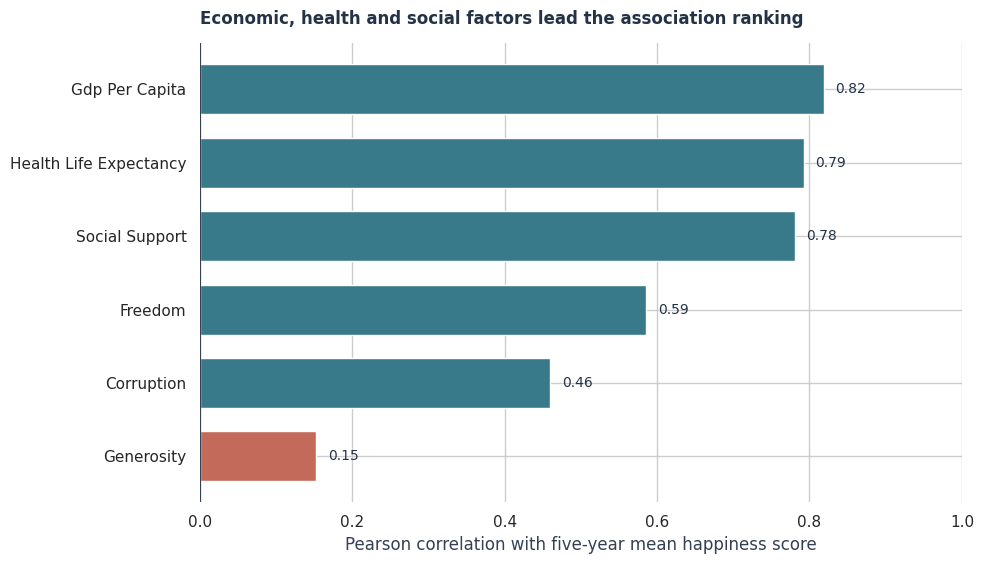

In [10]:
plot_corr = country_correlations.sort_values()
fig, ax = plt.subplots(figsize=(10, 5.8))
bar_colors = ["#C46A5B" if value < 0.3 else "#397A8A" for value in plot_corr.values]
bars = ax.barh(plot_corr.index.str.replace("_", " ").str.title(), plot_corr.values, color=bar_colors, height=0.68)
ax.axvline(0, color="#344054", linewidth=0.8)
ax.set_xlim(0, 1)
ax.set_xlabel("Pearson correlation with five-year mean happiness score")
ax.set_title("Economic, health and social factors lead the association ranking", loc="left", pad=14)
for bar, value in zip(bars, plot_corr.values):
    ax.text(value + 0.015, bar.get_y() + bar.get_height()/2, f"{value:.2f}", va="center", fontsize=10)
sns.despine(left=True, bottom=True)
plt.tight_layout()
plt.show()

### The upper and lower ends of the country distribution

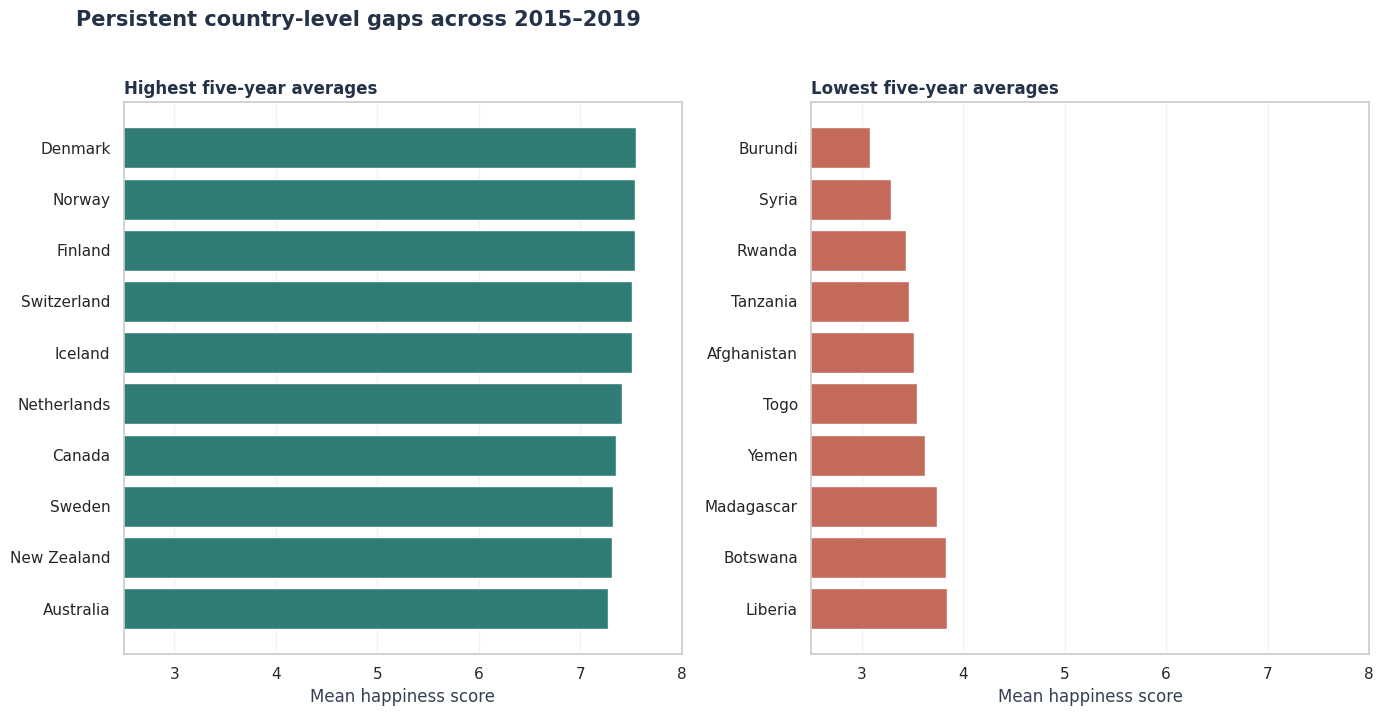

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 7), sharex=True)

top_plot = average_scores.head(10).sort_values()
bottom_plot = average_scores.tail(10).sort_values(ascending=False)

axes[0].barh(top_plot.index, top_plot.values, color="#2F7D75")
axes[0].set_title("Highest five-year averages", loc="left")
axes[0].set_xlabel("Mean happiness score")
axes[0].set_xlim(2.5, 8)

axes[1].barh(bottom_plot.index, bottom_plot.values, color="#C46A5B")
axes[1].set_title("Lowest five-year averages", loc="left")
axes[1].set_xlabel("Mean happiness score")
axes[1].set_xlim(2.5, 8)

for ax in axes:
    ax.grid(axis="x", alpha=0.25)
    ax.grid(axis="y", visible=False)

fig.suptitle("Persistent country-level gaps across 2015–2019", x=0.06, y=1.02, ha="left", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()

### The largest gains and declines, 2015 to 2019

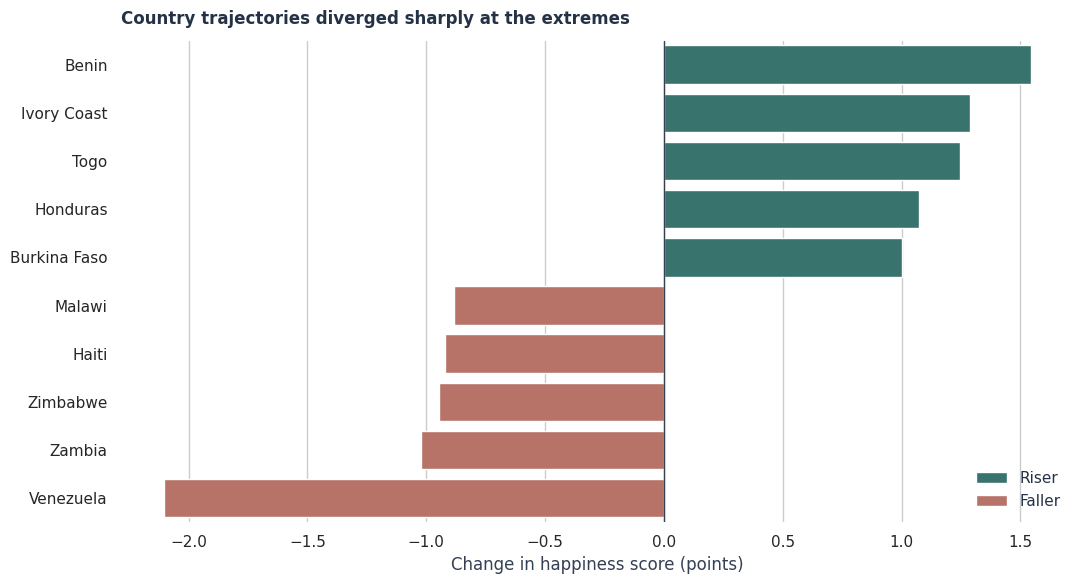

In [12]:
movement_plot = movement_table.reset_index().rename(columns={"index": "country"})
movement_plot["country"] = movement_plot["country"].astype(str)

fig, ax = plt.subplots(figsize=(11, 6))
palette = {"Riser": "#2F7D75", "Faller": "#C46A5B"}
sns.barplot(
    data=movement_plot,
    y="country",
    x="change_2015_2019",
    hue="direction",
    dodge=False,
    palette=palette,
    ax=ax
)
ax.axvline(0, color="#344054", linewidth=1)
ax.set_xlabel("Change in happiness score (points)")
ax.set_ylabel("")
ax.set_title("Country trajectories diverged sharply at the extremes", loc="left", pad=12)
ax.legend(title="", frameon=False, loc="lower right")
sns.despine(left=True, bottom=True)
plt.tight_layout()
plt.show()

### Regional averages in the editions with regional labels

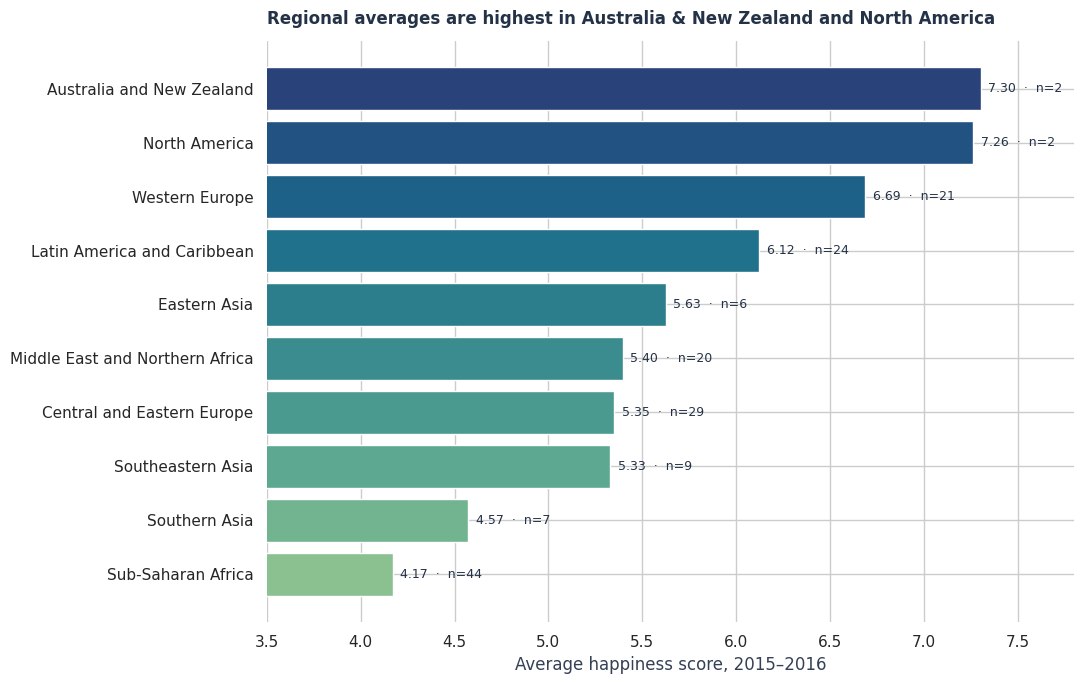

In [13]:
region_plot = regional_summary.sort_values("average_score")
fig, ax = plt.subplots(figsize=(11, 7))
colors = sns.color_palette("crest", n_colors=len(region_plot))
bars = ax.barh(region_plot.index, region_plot["average_score"], color=colors)
ax.set_xlim(3.5, 7.8)
ax.set_xlabel("Average happiness score, 2015–2016")
ax.set_title("Regional averages are highest in Australia & New Zealand and North America", loc="left", pad=12)
for bar, row in zip(bars, region_plot.itertuples()):
    ax.text(row.average_score + 0.04, bar.get_y() + bar.get_height()/2,
            f"{row.average_score:.2f}  ·  n={row.country_count}", va="center", fontsize=9)
sns.despine(left=True, bottom=True)
plt.tight_layout()
plt.show()

### GDP per capita and happiness in the 2019 cross-section

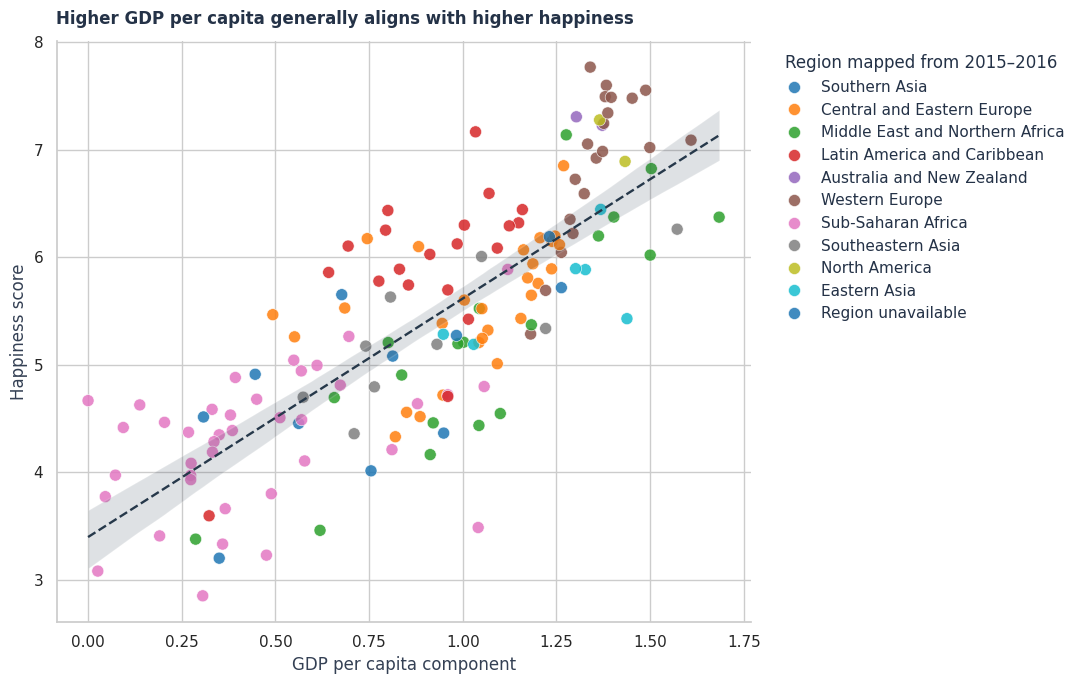

In [14]:
fig, ax = plt.subplots(figsize=(11, 7))
sns.scatterplot(
    data=happiness_2019,
    x="gdp_per_capita",
    y="happiness_score",
    hue="region_for_plot",
    palette="tab10",
    s=75,
    alpha=0.85,
    edgecolor="white",
    linewidth=0.45,
    ax=ax
)
sns.regplot(
    data=happiness_2019,
    x="gdp_per_capita",
    y="happiness_score",
    scatter=False,
    color="#26384A",
    line_kws={"linewidth": 1.7, "linestyle": "--"},
    ax=ax
)
ax.set_xlabel("GDP per capita component")
ax.set_ylabel("Happiness score")
ax.set_title("Higher GDP per capita generally aligns with higher happiness", loc="left", pad=12)
ax.legend(title="Region mapped from 2015–2016", bbox_to_anchor=(1.02, 1), loc="upper left", frameon=False)
sns.despine()
plt.tight_layout()
plt.show()

### High generosity does not guarantee a high score

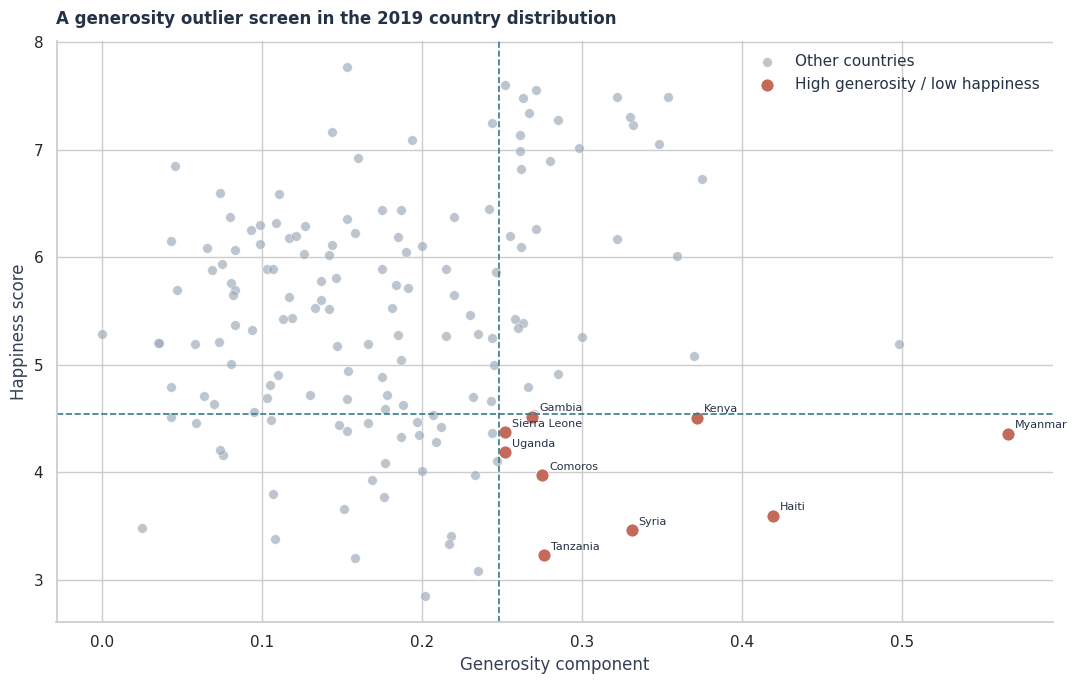

In [15]:
fig, ax = plt.subplots(figsize=(11, 7))
ax.scatter(
    happiness_2019["generosity"],
    happiness_2019["happiness_score"],
    s=48,
    color="#9AA8B6",
    alpha=0.65,
    edgecolor="white",
    linewidth=0.4,
    label="Other countries"
)
ax.scatter(
    generosity_outliers["generosity"],
    generosity_outliers["happiness_score"],
    s=90,
    color="#C46A5B",
    edgecolor="white",
    linewidth=0.7,
    label="High generosity / low happiness"
)
ax.axvline(generosity_cutoff, color="#397A8A", linestyle="--", linewidth=1.2)
ax.axhline(happiness_cutoff, color="#397A8A", linestyle="--", linewidth=1.2)

for row in generosity_outliers.itertuples():
    ax.annotate(row.country, (row.generosity, row.happiness_score),
                xytext=(5, 4), textcoords="offset points", fontsize=8)

ax.set_xlabel("Generosity component")
ax.set_ylabel("Happiness score")
ax.set_title("A generosity outlier screen in the 2019 country distribution", loc="left", pad=12)
ax.legend(frameon=False)
sns.despine()
plt.tight_layout()
plt.show()

### Score distributions by edition

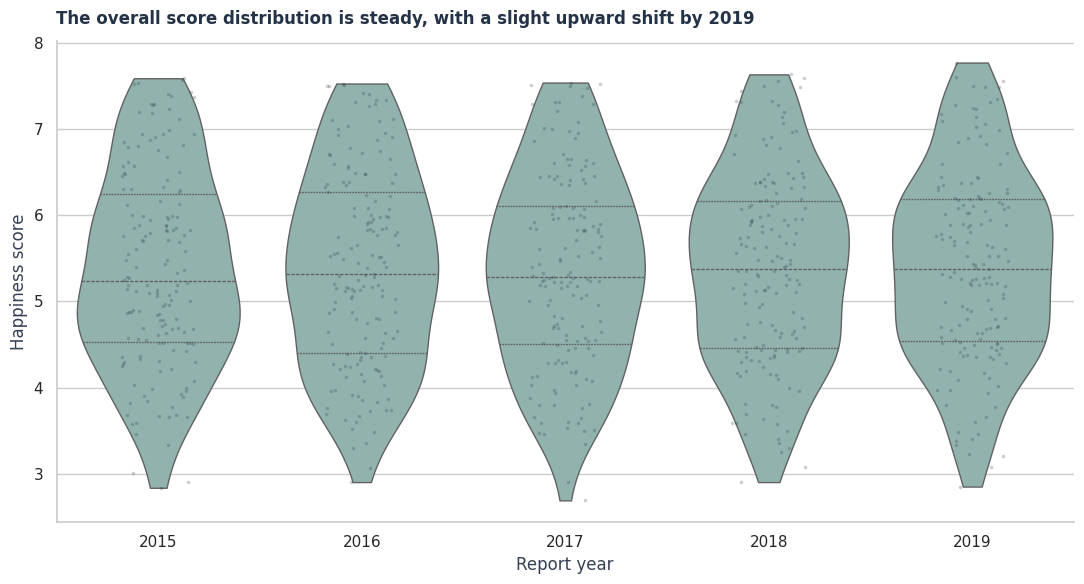

In [16]:
fig, ax = plt.subplots(figsize=(11, 6))
sns.violinplot(
    data=happiness,
    x="year",
    y="happiness_score",
    inner="quartile",
    cut=0,
    color="#8CB8B0",
    linewidth=1,
    ax=ax
)
sns.stripplot(
    data=happiness,
    x="year",
    y="happiness_score",
    color="#26384A",
    size=2.5,
    alpha=0.25,
    jitter=0.18,
    ax=ax
)
ax.set_xlabel("Report year")
ax.set_ylabel("Happiness score")
ax.set_title("The overall score distribution is steady, with a slight upward shift by 2019", loc="left", pad=12)
sns.despine()
plt.tight_layout()
plt.show()

### Five-year score path for the top 20 countries

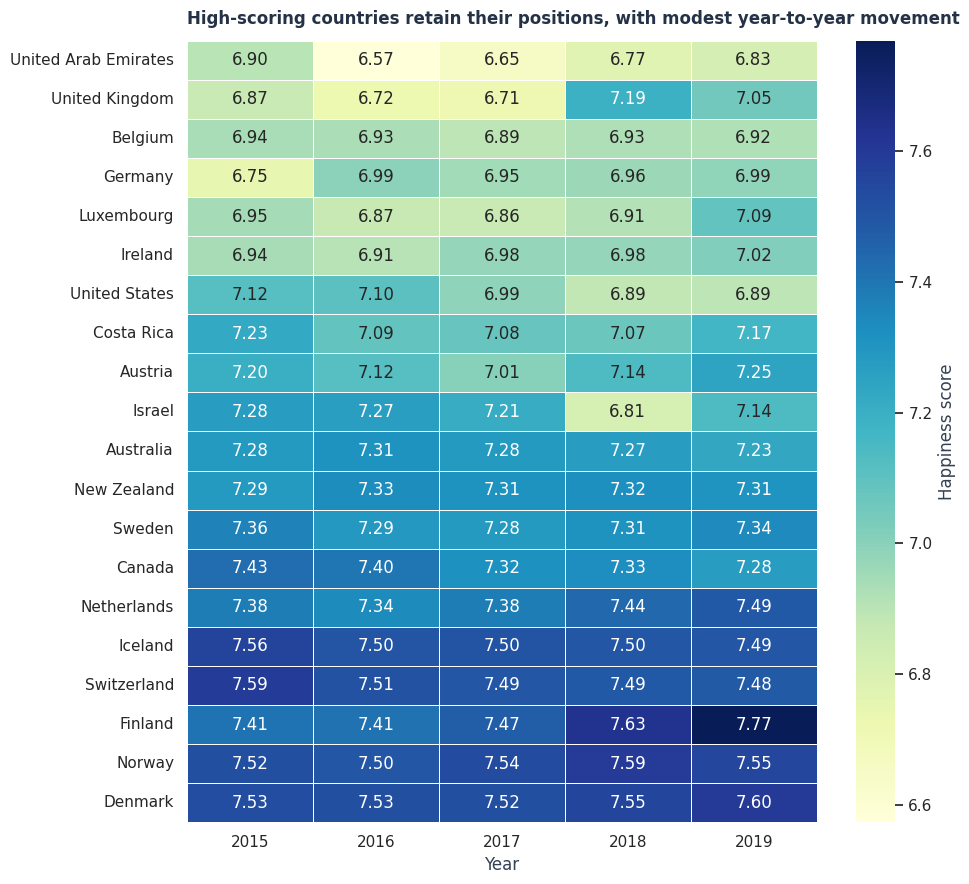

year,2015,2016,2017,2018,2019
country,,,,,
United Arab Emirates,6.901,6.573,6.648,6.774,6.825
United Kingdom,6.867,6.725,6.714,7.190,7.054
Belgium,6.937,6.929,6.891,6.927,6.923
Germany,6.750,6.994,6.951,6.965,6.985
Luxembourg,6.946,6.871,6.863,6.910,7.090
Ireland,6.940,6.907,6.977,6.977,7.021
United States,7.119,7.104,6.993,6.886,6.892
Costa Rica,7.226,7.087,7.079,7.072,7.167
Austria,7.200,7.119,7.006,7.139,7.246


In [17]:
top_20_countries = average_scores.head(20).index
top_20_pivot = score_pivot.loc[top_20_countries].copy()
top_20_pivot = top_20_pivot.loc[top_20_pivot.mean(axis=1).sort_values().index]

fig, ax = plt.subplots(figsize=(10, 9))
sns.heatmap(
    top_20_pivot,
    cmap="YlGnBu",
    annot=True,
    fmt=".2f",
    linewidths=0.45,
    linecolor="white",
    cbar_kws={"label": "Happiness score"},
    ax=ax
)
ax.set_xlabel("Year")
ax.set_ylabel("")
ax.set_title("High-scoring countries retain their positions, with modest year-to-year movement", loc="left", pad=12)
plt.tight_layout()
plt.show()

display(top_20_pivot.round(3))

### Driver consistency from year to year

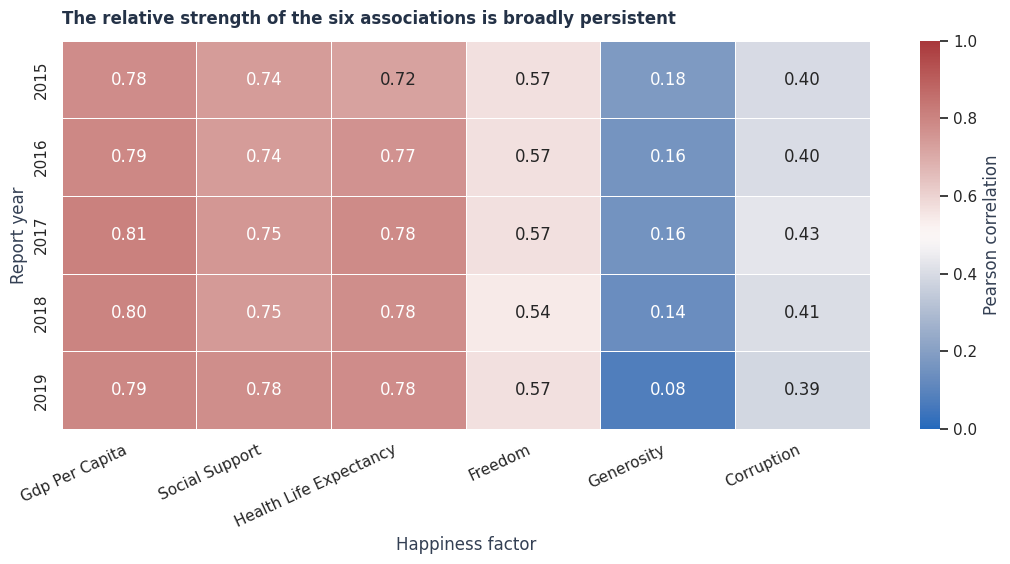

In [18]:
fig, ax = plt.subplots(figsize=(11, 5.8))
sns.heatmap(
    yearly_correlations,
    annot=True,
    fmt=".2f",
    cmap="vlag",
    center=0.5,
    vmin=0,
    vmax=1,
    linewidths=0.5,
    cbar_kws={"label": "Pearson correlation"},
    ax=ax
)
ax.set_xlabel("Happiness factor")
ax.set_ylabel("Report year")
ax.set_title("The relative strength of the six associations is broadly persistent", loc="left", pad=12)
ax.set_xticklabels([label.get_text().replace("_", " ").title() for label in ax.get_xticklabels()], rotation=25, ha="right")
plt.tight_layout()
plt.show()

### Countries with the most and least score variation

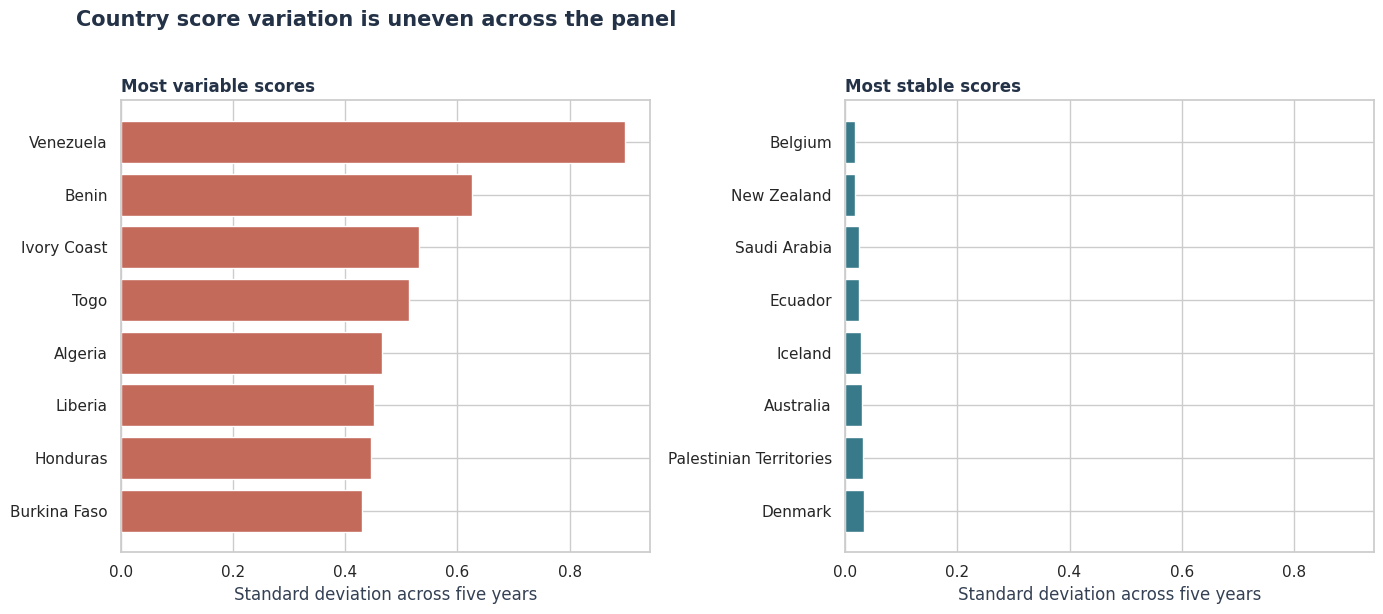

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharex=True)

volatile_plot = most_volatile.sort_values("score_std")
stable_plot = most_stable.sort_values("score_std", ascending=False)

axes[0].barh(volatile_plot.index, volatile_plot["score_std"], color="#C46A5B")
axes[0].set_title("Most variable scores", loc="left")
axes[0].set_xlabel("Standard deviation across five years")

axes[1].barh(stable_plot.index, stable_plot["score_std"], color="#397A8A")
axes[1].set_title("Most stable scores", loc="left")
axes[1].set_xlabel("Standard deviation across five years")

fig.suptitle("Country score variation is uneven across the panel", x=0.06, y=1.02, ha="left", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()

## Interactive country explorer

The animated scatter follows the GDP–happiness relationship across all five report years. The play control changes the year, while hover details retain the country-level values. Region labels for 2017–2019 are carried forward from the 2015–2016 regional lookup and are marked as unavailable where no match exists.

In [20]:
pio.renderers.default = "plotly_mimetype"

interactive_panel = happiness.copy()
interactive_panel["region_for_plot"] = (
    interactive_panel["country"].map(region_lookup)
    .fillna(interactive_panel["region"])
    .fillna("Region unavailable")
)

fig = px.scatter(
    interactive_panel,
    x="gdp_per_capita",
    y="happiness_score",
    animation_frame="year",
    animation_group="country",
    color="region_for_plot",
    size="social_support",
    size_max=18,
    hover_name="country",
    hover_data={
        "year": True,
        "gdp_per_capita": ":.3f",
        "social_support": ":.3f",
        "health_life_expectancy": ":.3f",
        "freedom": ":.3f",
        "generosity": ":.3f",
        "corruption": ":.3f",
        "region_for_plot": True
    },
    range_x=[0, 1.9],
    range_y=[2.3, 8.0],
    title="GDP per capita and happiness | 2015–2019"
)

fig.update_layout(
    template="plotly_white",
    height=680,
    width=1120,
    legend_title_text="Region",
    title_x=0.03,
    margin=dict(l=55, r=35, t=80, b=55)
)
fig.update_xaxes(title="GDP per capita component")
fig.update_yaxes(title="Happiness score")
fig.show()

## Reference tables

The country-year pivot and the change table remain available as compact reference outputs. No separate closing interpretation section is appended; the strategic findings and methodological boundaries are documented in `note.md`.

In [21]:
display(score_pivot.head(20).round(3))
display(change_table.sort_values("change_2015_2019", ascending=False).head(10).round(3))
display(change_table.sort_values("change_2015_2019").head(10).round(3))

year,2015,2016,2017,2018,2019
country,,,,,
Afghanistan,3.575,3.360,3.794,3.632,3.203
Albania,4.959,4.655,4.644,4.586,4.719
Algeria,5.605,6.355,5.872,5.295,5.211
Argentina,6.574,6.650,6.599,6.388,6.086
Armenia,4.350,4.360,4.376,4.321,4.559
Australia,7.284,7.313,7.284,7.272,7.228
Austria,7.200,7.119,7.006,7.139,7.246
Azerbaijan,5.212,5.291,5.234,5.201,5.208
Bahrain,5.960,6.218,6.087,6.105,6.199


year,2015,2019,change_2015_2019
country,,,
Benin,3.340,4.883,1.543
Ivory Coast,3.655,4.944,1.289
Togo,2.839,4.085,1.246
Honduras,4.788,5.860,1.072
Burkina Faso,3.587,4.587,1.000
Hungary,4.800,5.758,0.958
Romania,5.124,6.070,0.946
Gabon,3.896,4.799,0.903
Cambodia,3.819,4.700,0.881


year,2015,2019,change_2015_2019
country,,,
Venezuela,6.810,4.707,-2.103
Zambia,5.129,4.107,-1.022
Zimbabwe,4.610,3.663,-0.947
Haiti,4.518,3.597,-0.921
Malawi,4.292,3.410,-0.882
Botswana,4.332,3.488,-0.844
Yemen,4.077,3.380,-0.697
Brazil,6.983,6.300,-0.683
Liberia,4.571,3.975,-0.596
